In [94]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler


In [95]:
# 도미 - 35
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어  - 14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]



In [96]:
# 데이터 전처리 
total_lenght = bream_length + smelt_length
total_weight = bream_weight + smelt_weight
# data = [[l,w] for l,w in zip(total_lenght,total_weight)]
# data2 = np.array(data)
data = np.column_stack((total_lenght,total_weight))
label = ['도미']*35 + ['빙어']*14
# label = [1]*35 + [0]*14

In [77]:
# 정규화 작업
# 표준점수 = (특성값-산술평균)/표준편차
mean = np.mean(data,axis=0) #행의 기준으로 산술평균
std = np.std(data,axis=0)   #행의 기준으로 표준편차
train_scaled = (data-mean) / std


In [97]:
# 정규화 작업
ss = StandardScaler()               # 정규화 선언
ss.fit(data)                        #정규화 학습
train_scaled = ss.transform(data)   #정규화변환
train_data,test_data,train_label,test_label = train_test_split(train_scaled,label)

train_data

array([[ 0.58641218,  0.78669225],
       [ 0.4384503 ,  0.17088618],
       [ 1.12893906,  1.57184499],
       [ 1.12893906,  1.46407893],
       [-1.18913036, -1.30735628],
       [ 0.6357328 ,  0.50957952],
       [-1.62315187, -1.34707578],
       [ 0.48777093,  0.47878922],
       [ 0.68505343,  0.7405068 ],
       [ 0.78369468,  0.84827286],
       [-0.16326134, -0.62350364],
       [-1.56396712, -1.33845449],
       [ 0.68505343,  0.40181346],
       [ 0.3595373 ,  0.17088618],
       [ 0.88233593,  0.82979868],
       [ 0.26089605,  0.17088618],
       [ 1.37554219,  1.6334256 ],
       [ 0.98097719,  1.71040136],
       [ 0.6357328 ,  0.63274074],
       [-0.07448421, -0.47571019],
       [ 0.48777093, -0.32175867],
       [ 1.22758032,  1.47947408],
       [-1.63301599, -1.34553626],
       [-1.58369537, -1.33876239],
       [-1.55410299, -1.34184142],
       [ 0.78369468,  0.86366801],
       [-1.38641286, -1.33106482],
       [-1.50478237, -1.33814659],
       [ 0.26089605,

In [78]:
# 학습데이터 , 테스트데이터 분류
train_data,test_data,train_label,test_label = \
    train_test_split(train_scaled,label)


In [98]:

#데이터 학습 , 데이터 예측 , 정확도

clf = KNeighborsClassifier()
clf.fit(train_data,train_label)

result = clf.predict(test_data) 

score = clf.score(test_data,test_label)             # 테스트데이터를 가지고 어느정도 정답을 맞췄는지 확인
# score = metrics.accuracy_score(result,test_label)   # 예측되어서 나온 값과 실제정답과 비교
print('정확도 : ',score)

정확도 :  1.0


In [80]:
# input1 = '25,120'
# input1 = input1.split(',')
# input1
# input2 = list(map(float,input1))
# input2

In [99]:
## input 받아서 도미인지, 빙어인지 확인하시오.
## 길이,무게 
input1 = input('생선의 길이와 무게를 입력하시오. 예) 25,120 ')
input1 = input1.split(',')
input1
input2 = list(map(float,input1))
input2
new_input = (input2-mean)/std
result2 = clf.predict([new_input])
print("예측생선 : ",result2)

예측생선 :  ['도미']


In [100]:
distances, indexes = clf.kneighbors([new_input]) #도미로 판단하게 된 데이터가 어떤것인지 알려줌.
distances
indexes

array([[10, 19, 35, 20,  4]])

In [83]:
# #그래프 출력
# plt.scatter(data[:,0],data[:,1])
# plt.xlabel('길이')
# plt.ylabel('무게')
# plt.show()

1. 데이터전처리
2. 정규화작업
3. 학습데이터 , 테스트데이터 분리
4. 데이터학습 , 데이터예측, 정확도
5. 산점도 그래프

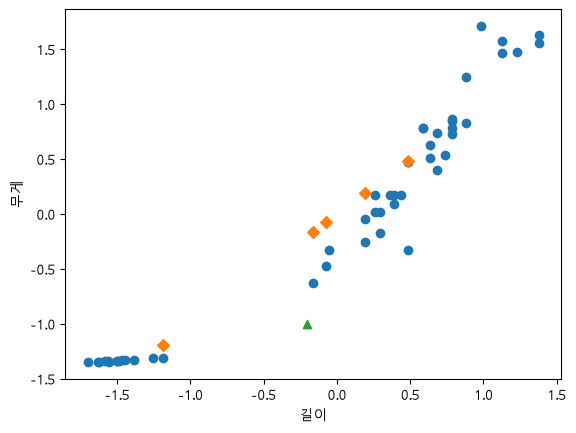

In [101]:
#그래프 출력
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(train_data[indexes,0],train_data[indexes,0],marker='D')
plt.scatter(new_input[0],new_input[1],marker='^')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()